# 🎬 Урок 1. OpenCV: картинка → кадр → видео

**Часть 1** — учимся работать с картинкой: открыть, узнать размер, обрезать, повернуть, нарисовать.
**Часть 2** — видео: это много картинок подряд. Достаём кадры, меняем каждый и сохраняем.

**Как устроено каждое задание**
1. Короткое объяснение и пример.
2. **Задание ✏️** — в ячейке замените `None` на свой код и запустите (**Shift + Enter**).
3. **🧪 Проверка** — запустите ячейку под заданием. Тесты покажут ✅ или ❌ и подскажут, что не так.
4. Застряли — откройте **💡 Подсказку**, потом **🆘 Почти готовый ответ**.

> Сначала: **Файл → Сохранить копию на Диске**, иначе работа пропадёт. Шпаргалка по всем функциям — в конце.

In [1]:
# Подключаем библиотеки
import cv2                                   # OpenCV — картинки и видео
import numpy as np                           # numpy — массивы чисел (картинка — это массив)
from google.colab.patches import cv2_imshow  # показ картинки в Colab (обычный cv2.imshow здесь не работает)

# Скачиваем учебные картинки. «!» — команда для сервера Colab, качает он, а не ваш интернет
!wget -q -nc https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/fruits.jpg
!wget -q -nc https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/baboon.jpg
print("Готово! OpenCV версии", cv2.__version__)

Готово! OpenCV версии 5.0.0


---
# Часть 1. Картинка

## 1. Открыть и показать
`cv2.imread("файл")` читает картинку, `cv2_imshow(картинка)` показывает её.

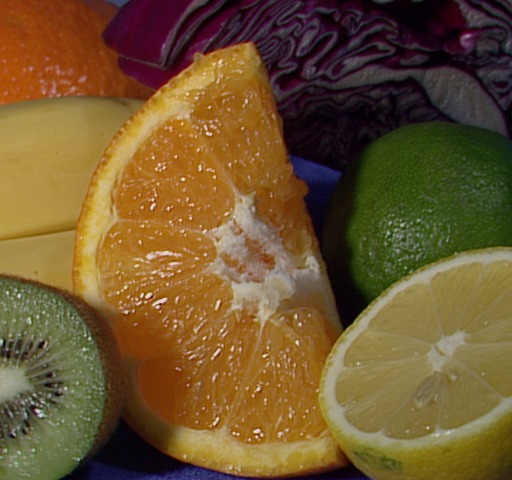

In [12]:
img = cv2.imread("fruits.jpg")
cv2_imshow(img)

> ⚠️ Если в имени файла опечатка, `imread` не ругается, а возвращает `None`. Ошибка вылезет позже: *'NoneType' object has no attribute…*

### ✏️ Задание 1. Прочитайте картинку `baboon.jpg` в переменную `img2`

**Что должно получиться:** под проверкой появится обезьяна-мандрил.

In [2]:
img2 = cv2.imread("baboon.jpg")

✅ Тест 1: картинка прочитана (не None)
✅ Тест 2: размер 512×512, 3 канала

🎉 Задание 1 выполнено! Пройдено тестов: 2 из 2


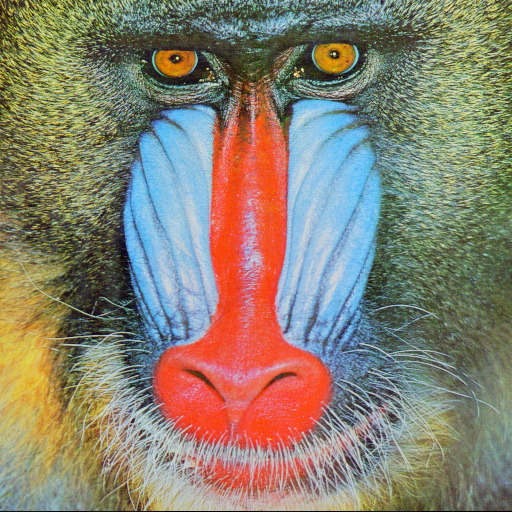

In [3]:
#@title 🧪 Проверка задания 1 { display-mode: "form" }
def _check(tests):
    for i, (name, cond, hint) in enumerate(tests, 1):
        try:
            passed = bool(cond())
        except Exception:
            passed = False
        if not passed:
            print(f"❌ Тест {i} из {len(tests)}: {name}")
            print(f"   💡 {hint}")
            return False
        print(f"✅ Тест {i}: {name}")
    print(f"\n🎉 Задание 1 выполнено! Пройдено тестов: {len(tests)} из {len(tests)}")
    return True

if _check([
    ('картинка прочитана (не None)', lambda: img2 is not None, 'Проверьте имя файла: "baboon.jpg", в кавычках'),
    ('размер 512×512, 3 канала', lambda: img2.shape == (512, 512, 3), 'Прочитали не тот файл?'),
]):
    cv2_imshow(img2)

<details><summary>💡 Подсказка</summary>

Так же, как в примере выше, только другое имя файла.
</details>
<details><summary>🆘 Почти готовый ответ</summary>

```python
img2 = cv2.imread("___")
```
</details>

## 2. Размер — `shape`
Картинка — это таблица чисел. `img.shape` = **(высота, ширина, каналы)**. Каналов 3: синий, зелёный, красный. Элементы достаём по номеру, считая с **0**: `img.shape[0]` — высота.

In [13]:
print(img.shape)

(480, 512, 3)


### ✏️ Задание 2. Достаньте высоту, ширину и число каналов в переменные `h`, `w`, `c`

In [14]:
h = img.shape[0]  # высота
w = img.shape[1] # ширина
c = img.shape[2] # каналы

In [15]:
#@title 🧪 Проверка задания 2 { display-mode: "form" }
def _check(tests):
    for i, (name, cond, hint) in enumerate(tests, 1):
        try:
            passed = bool(cond())
        except Exception:
            passed = False
        if not passed:
            print(f"❌ Тест {i} из {len(tests)}: {name}")
            print(f"   💡 {hint}")
            return False
        print(f"✅ Тест {i}: {name}")
    print(f"\n🎉 Задание 2 выполнено! Пройдено тестов: {len(tests)} из {len(tests)}")
    return True

if _check([
    ('h — высота', lambda: h == img.shape[0], 'Высота — элемент номер 0: img.shape[0]'),
    ('w — ширина', lambda: w == img.shape[1], 'Ширина — элемент номер 1'),
    ('c — каналы', lambda: c == img.shape[2], 'Каналы — элемент номер 2'),
]):
    print("высота", h, "ширина", w, "каналы", c)

✅ Тест 1: h — высота
✅ Тест 2: w — ширина
✅ Тест 3: c — каналы

🎉 Задание 2 выполнено! Пройдено тестов: 3 из 3
высота 480 ширина 512 каналы 3


<details><summary>💡 Подсказка</summary>

Порядок в `shape`: высота (0), ширина (1), каналы (2).
</details>
<details><summary>🆘 Почти готовый ответ</summary>

```python
h = img.shape[0]
w = img.shape[___]
c = img.shape[___]
```
</details>

### ✏️ Задание 3. Сколько всего пикселей в картинке? Запишите в `pixels`

In [16]:
pixels = h * w

In [17]:
#@title 🧪 Проверка задания 3 { display-mode: "form" }
def _check(tests):
    for i, (name, cond, hint) in enumerate(tests, 1):
        try:
            passed = bool(cond())
        except Exception:
            passed = False
        if not passed:
            print(f"❌ Тест {i} из {len(tests)}: {name}")
            print(f"   💡 {hint}")
            return False
        print(f"✅ Тест {i}: {name}")
    print(f"\n🎉 Задание 3 выполнено! Пройдено тестов: {len(tests)} из {len(tests)}")
    return True

if _check([
    ('число пикселей верное', lambda: pixels == img.shape[0] * img.shape[1], 'Сколько клеток в таблице высотой h и шириной w?'),
]):
    print("Пикселей:", pixels, "— и в каждом по 3 числа")

✅ Тест 1: число пикселей верное

🎉 Задание 3 выполнено! Пройдено тестов: 1 из 1
Пикселей: 245760 — и в каждом по 3 числа


<details><summary>💡 Подсказка</summary>

Пиксели — клетки прямоугольника h × w.
</details>
<details><summary>🆘 Почти готовый ответ</summary>

```python
pixels = h * ___
```
</details>

## 3. Какие числа внутри
Тип `uint8` — целые числа от **0 до 255**. `img.min()` и `img.max()` — самое маленькое и самое большое из них.

In [18]:
print("тип:", img.dtype, " минимум:", img.min(), " максимум:", img.max())

тип: uint8  минимум: 0  максимум: 252


### ✏️ Задание 4. Найдите самое большое число в картинке `img2`

In [19]:
biggest = img2.max()

In [20]:
#@title 🧪 Проверка задания 4 { display-mode: "form" }
def _check(tests):
    for i, (name, cond, hint) in enumerate(tests, 1):
        try:
            passed = bool(cond())
        except Exception:
            passed = False
        if not passed:
            print(f"❌ Тест {i} из {len(tests)}: {name}")
            print(f"   💡 {hint}")
            return False
        print(f"✅ Тест {i}: {name}")
    print(f"\n🎉 Задание 4 выполнено! Пройдено тестов: {len(tests)} из {len(tests)}")
    return True

if _check([
    ('максимум найден', lambda: biggest == img2.max(), 'Как в примере, только для img2: img2.max()'),
]):
    print("Максимум:", biggest)

✅ Тест 1: максимум найден

🎉 Задание 4 выполнено! Пройдено тестов: 1 из 1
Максимум: 255


<details><summary>💡 Подсказка</summary>

Метод `.max()` у картинки `img2`.
</details>
<details><summary>🆘 Почти готовый ответ</summary>

```python
biggest = img2.___()
```
</details>

## 4. Один пиксель
`img[y, x]` — сначала **строка** (сверху вниз), потом **столбец** (слева направо). Ответ — три числа **[синий, зелёный, красный]**: OpenCV хранит цвета в порядке **BGR**.

In [21]:
print("Пиксель в строке 10, столбце 20:", img[10, 20])

Пиксель в строке 10, столбце 20: [ 15  62 148]


### ✏️ Задание 5. Достаньте пиксель из центра картинки

In [25]:
center = img2[h // 2, w // 2]

In [24]:
#@title 🧪 Проверка задания 5 { display-mode: "form" }
def _check(tests):
    for i, (name, cond, hint) in enumerate(tests, 1):
        try:
            passed = bool(cond())
        except Exception:
            passed = False
        if not passed:
            print(f"❌ Тест {i} из {len(tests)}: {name}")
            print(f"   💡 {hint}")
            return False
        print(f"✅ Тест {i}: {name}")
    print(f"\n🎉 Задание 5 выполнено! Пройдено тестов: {len(tests)} из {len(tests)}")
    return True

if _check([
    ('это пиксель из 3 чисел', lambda: len(center) == 3, 'Нужно img[строка, столбец]'),
    ('это именно центр', lambda: (center == img[img.shape[0] // 2, img.shape[1] // 2]).all(), 'Строка центра — h // 2, столбец — w // 2'),
]):
    print("Центр (B, G, R):", center)

✅ Тест 1: это пиксель из 3 чисел
❌ Тест 2 из 2: это именно центр
   💡 Строка центра — h // 2, столбец — w // 2


<details><summary>💡 Подсказка</summary>

Центр — половина высоты и половина ширины. Сначала строка!
</details>
<details><summary>🆘 Почти готовый ответ</summary>

```python
center = img[h // 2, ___]
```
</details>

## 5. Закрасить кусок
`картинка[строки, столбцы] = (B, G, R)` закрашивает прямоугольник. `0:50` — с 0 по 49, `:` — всё. Сначала делаем копию `.copy()`, чтобы не испортить оригинал.

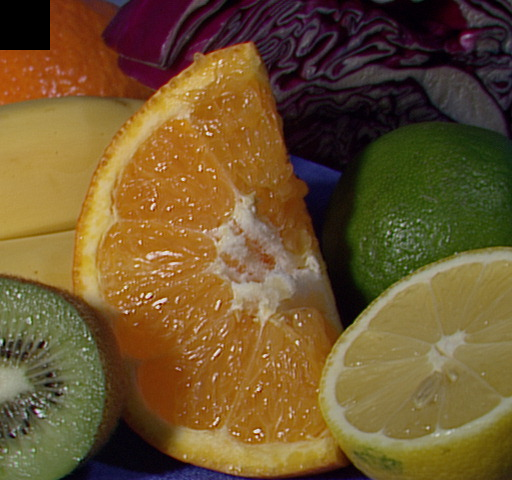

In [26]:
pic = img.copy()
pic[0:50, 0:50] = (0, 0, 0)     # чёрный квадрат в левом верхнем углу
cv2_imshow(pic)

### ✏️ Задание 6. Нарисуйте красную полосу высотой 20 пикселей через весь верх картинки

In [27]:
stripe = img.copy()
# ↓ ваш код (красный в BGR — (0, 0, 255))
stripe[0:20, :] = (0, 0, 255)

✅ Тест 1: верхние 20 строк красные
✅ Тест 2: остальное не тронуто

🎉 Задание 6 выполнено! Пройдено тестов: 2 из 2


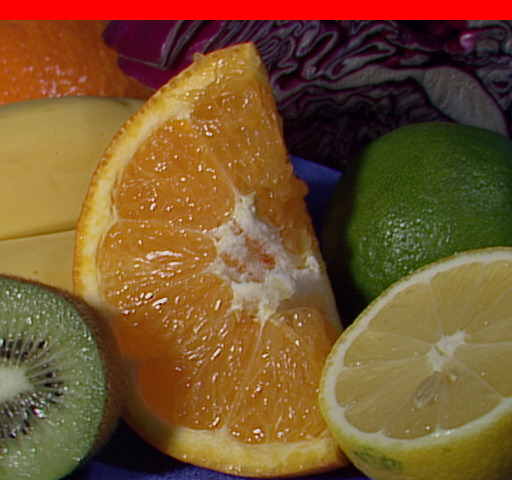

In [28]:
#@title 🧪 Проверка задания 6 { display-mode: "form" }
def _check(tests):
    for i, (name, cond, hint) in enumerate(tests, 1):
        try:
            passed = bool(cond())
        except Exception:
            passed = False
        if not passed:
            print(f"❌ Тест {i} из {len(tests)}: {name}")
            print(f"   💡 {hint}")
            return False
        print(f"✅ Тест {i}: {name}")
    print(f"\n🎉 Задание 6 выполнено! Пройдено тестов: {len(tests)} из {len(tests)}")
    return True

if _check([
    ('верхние 20 строк красные', lambda: (stripe[0:20, :] == (0, 0, 255)).all(), 'Строки 0:20, столбцы — все (:), цвет (0, 0, 255)'),
    ('остальное не тронуто', lambda: (stripe[20:] == img[20:]).all(), 'Закрашено лишнее — проверьте 0:20'),
]):
    cv2_imshow(stripe)

<details><summary>💡 Подсказка</summary>

Строки `0:20`, столбцы — все, то есть `:`.
</details>
<details><summary>🆘 Почти готовый ответ</summary>

```python
stripe[0:20, ___] = (0, 0, 255)
```
</details>

## 6. Вырезать кусок
Тот же срез, только без `=`: `кусок = img[строки, столбцы]`.

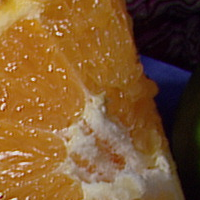

In [29]:
piece = img[100:300, 150:350]
cv2_imshow(piece)

### ✏️ Задание 7. Вырежьте левую половину картинки

In [30]:
left =  img2 [:, :w // 2]

In [31]:
#@title 🧪 Проверка задания 7 { display-mode: "form" }
def _check(tests):
    for i, (name, cond, hint) in enumerate(tests, 1):
        try:
            passed = bool(cond())
        except Exception:
            passed = False
        if not passed:
            print(f"❌ Тест {i} из {len(tests)}: {name}")
            print(f"   💡 {hint}")
            return False
        print(f"✅ Тест {i}: {name}")
    print(f"\n🎉 Задание 7 выполнено! Пройдено тестов: {len(tests)} из {len(tests)}")
    return True

if _check([
    ('что-то вырезано', lambda: left is not None, 'Нужен срез img[строки, столбцы]'),
    ('высота целиком, ширина — половина', lambda: left.shape == (img.shape[0], img.shape[1] // 2, 3), 'Строки — все (:), столбцы — :w // 2'),
    ('это именно левая половина', lambda: (left == img[:, : img.shape[1] // 2]).all(), 'Столбцы начинаются с 0'),
]):
    cv2_imshow(left)

✅ Тест 1: что-то вырезано
❌ Тест 2 из 3: высота целиком, ширина — половина
   💡 Строки — все (:), столбцы — :w // 2


<details><summary>💡 Подсказка</summary>

Строки — все (`:`), столбцы — от 0 до `w // 2`.
</details>
<details><summary>🆘 Почти готовый ответ</summary>

```python
left = img[:, 0:___]
```
</details>

## 7. Изменить размер — `cv2.resize`
`cv2.resize(картинка, (ширина, высота))`

⚠️ **Ловушка:** в `resize` сначала **ширина**, а в `shape` — высота.

In [ ]:
small = cv2.resize(img, (200, 100))   # ширина 200, высота 100
print("Было:", img.shape, "стало:", small.shape)

### ✏️ Задание 8. Уменьшите картинку ровно в 2 раза

In [32]:
half = cv2.resize(img2, (w //2, h // 2))

✅ Тест 1: картинка получена
✅ Тест 2: размер ровно в 2 раза меньше

🎉 Задание 8 выполнено! Пройдено тестов: 2 из 2


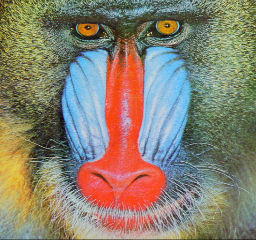

In [33]:
#@title 🧪 Проверка задания 8 { display-mode: "form" }
def _check(tests):
    for i, (name, cond, hint) in enumerate(tests, 1):
        try:
            passed = bool(cond())
        except Exception:
            passed = False
        if not passed:
            print(f"❌ Тест {i} из {len(tests)}: {name}")
            print(f"   💡 {hint}")
            return False
        print(f"✅ Тест {i}: {name}")
    print(f"\n🎉 Задание 8 выполнено! Пройдено тестов: {len(tests)} из {len(tests)}")
    return True

if _check([
    ('картинка получена', lambda: half is not None, 'Используйте cv2.resize(img, (ширина, высота))'),
    ('размер ровно в 2 раза меньше', lambda: half.shape == (img.shape[0] // 2, img.shape[1] // 2, 3), 'В resize сначала ширина (w // 2), потом высота (h // 2)'),
]):
    cv2_imshow(half)

<details><summary>💡 Подсказка</summary>

Новая ширина `w // 2`, высота `h // 2`. В скобках сначала ширина!
</details>
<details><summary>🆘 Почти готовый ответ</summary>

```python
half = cv2.resize(img, (___, ___))
```
</details>

## 8. Отражение — `cv2.flip`
`cv2.flip(картинка, код)`: `1` — влево-вправо (зеркало), `0` — вверх-вниз, `-1` — оба сразу.

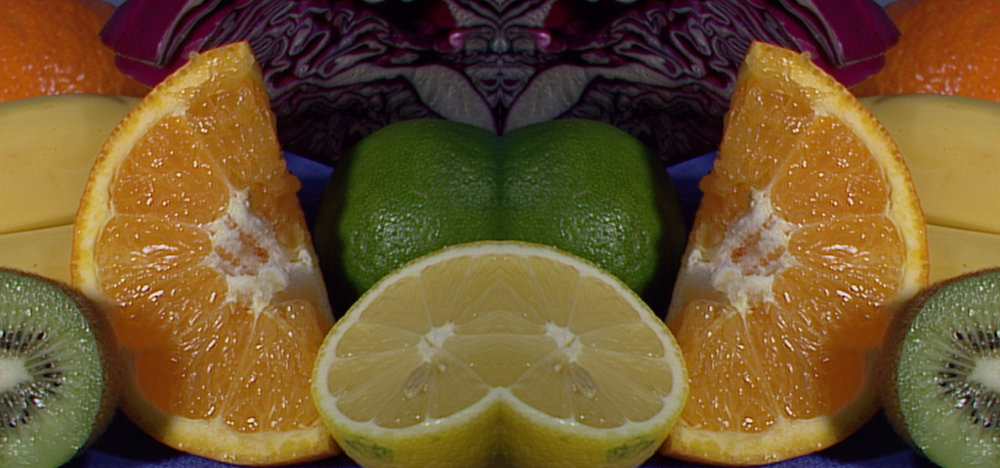

In [34]:
mirror = cv2.flip(img, 1)
cv2_imshow(np.hstack([img, mirror]))   # np.hstack ставит картинки рядом

### ✏️ Задание 9. Переверните картинку на 180° (вверх ногами)

In [35]:
upside = cv2.flip(img, -1)

✅ Тест 1: картинка получена
✅ Тест 2: это поворот на 180°

🎉 Задание 9 выполнено! Пройдено тестов: 2 из 2


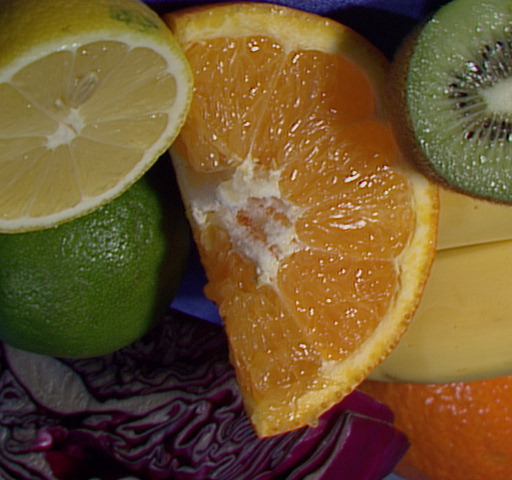

In [36]:
#@title 🧪 Проверка задания 9 { display-mode: "form" }
def _check(tests):
    for i, (name, cond, hint) in enumerate(tests, 1):
        try:
            passed = bool(cond())
        except Exception:
            passed = False
        if not passed:
            print(f"❌ Тест {i} из {len(tests)}: {name}")
            print(f"   💡 {hint}")
            return False
        print(f"✅ Тест {i}: {name}")
    print(f"\n🎉 Задание 9 выполнено! Пройдено тестов: {len(tests)} из {len(tests)}")
    return True

if _check([
    ('картинка получена', lambda: upside is not None, 'Используйте cv2.flip(img, код)'),
    ('это поворот на 180°', lambda: (upside == np.rot90(img, 2)).all(), 'Код 0 только переворачивает вверх-вниз. Нужно отразить по обеим осям'),
]):
    cv2_imshow(upside)

<details><summary>💡 Подсказка</summary>

180° = отражение вверх-вниз **и** влево-вправо сразу. Это будет на контрольной!
</details>
<details><summary>🆘 Почти готовый ответ</summary>

```python
upside = cv2.flip(img, ___)
```
</details>

## 9. Поворот на 90° — `cv2.rotate`
Константы: `cv2.ROTATE_90_CLOCKWISE` (по часовой), `cv2.ROTATE_90_COUNTERCLOCKWISE` (против), `cv2.ROTATE_180`.

In [39]:
turned = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)
print("Было:", img.shape, "стало:", turned.shape)   # высота и ширина поменялись

Было: (480, 512, 3) стало: (512, 480, 3)


### ✏️ Задание 10. Поверните картинку против часовой стрелки

In [37]:
ccw = cv2.rotate(img, cv2.ROTATE_90_COUNTERCLOCKWISE)

✅ Тест 1: картинка получена
✅ Тест 2: повёрнута против часовой

🎉 Задание 10 выполнено! Пройдено тестов: 2 из 2


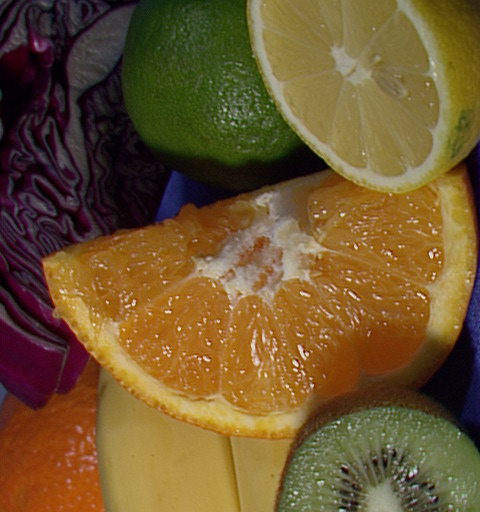

In [38]:
#@title 🧪 Проверка задания 10 { display-mode: "form" }
def _check(tests):
    for i, (name, cond, hint) in enumerate(tests, 1):
        try:
            passed = bool(cond())
        except Exception:
            passed = False
        if not passed:
            print(f"❌ Тест {i} из {len(tests)}: {name}")
            print(f"   💡 {hint}")
            return False
        print(f"✅ Тест {i}: {name}")
    print(f"\n🎉 Задание 10 выполнено! Пройдено тестов: {len(tests)} из {len(tests)}")
    return True

if _check([
    ('картинка получена', lambda: ccw is not None, 'Используйте cv2.rotate(img, константа)'),
    ('повёрнута против часовой', lambda: (ccw == np.rot90(img, 1)).all(), 'Нужна константа ROTATE_90_COUNTERCLOCKWISE'),
]):
    cv2_imshow(ccw)

<details><summary>💡 Подсказка</summary>

Та же функция, другая константа из списка выше.
</details>
<details><summary>🆘 Почти готовый ответ</summary>

```python
ccw = cv2.rotate(img, cv2.ROTATE_90____)
```
</details>

## 10. Серая картинка — `cv2.cvtColor`
`cv2.cvtColor(картинка, cv2.COLOR_BGR2GRAY)` — «из BGR в серый». У серой картинки одно число на пиксель (яркость), поэтому `shape` = (высота, ширина).

In [40]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
print("Цветная:", img.shape, " серая:", gray.shape)

Цветная: (480, 512, 3)  серая: (480, 512)


### ✏️ Задание 11. Сделайте серой `img2` и узнайте яркость её центрального пикселя [256, 256]

In [41]:
gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)
bright = gray2[256, 256]

✅ Тест 1: gray2 серая (одно число на пиксель)
✅ Тест 2: яркость центра верная

🎉 Задание 11 выполнено! Пройдено тестов: 2 из 2


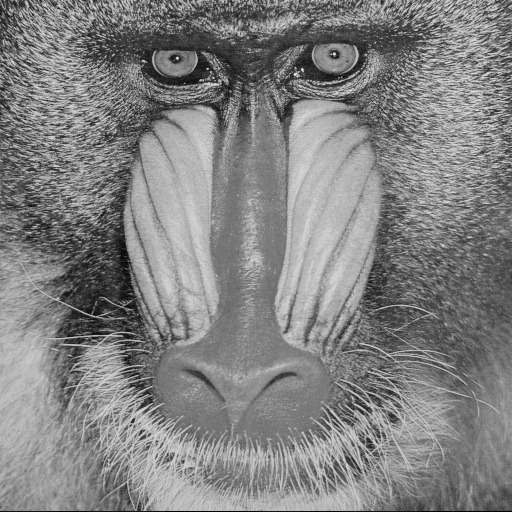

Яркость центра: 197


In [42]:
#@title 🧪 Проверка задания 11 { display-mode: "form" }
def _check(tests):
    for i, (name, cond, hint) in enumerate(tests, 1):
        try:
            passed = bool(cond())
        except Exception:
            passed = False
        if not passed:
            print(f"❌ Тест {i} из {len(tests)}: {name}")
            print(f"   💡 {hint}")
            return False
        print(f"✅ Тест {i}: {name}")
    print(f"\n🎉 Задание 11 выполнено! Пройдено тестов: {len(tests)} из {len(tests)}")
    return True

if _check([
    ('gray2 серая (одно число на пиксель)', lambda: gray2.ndim == 2, 'cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)'),
    ('яркость центра верная', lambda: bright == gray2[256, 256], 'Яркость — это gray2[строка, столбец]'),
]):
    cv2_imshow(gray2)
    print("Яркость центра:", bright)

<details><summary>💡 Подсказка</summary>

Первая строка — как в примере, с `img2`. Вторая — пиксель серой картинки.
</details>
<details><summary>🆘 Почти готовый ответ</summary>

```python
gray2 = cv2.cvtColor(___, cv2.COLOR_BGR2GRAY)
bright = gray2[256, ___]
```
</details>

## 11. Каналы B, G, R
`b, g, r = cv2.split(img)` раскладывает картинку на три серые: чем светлее, тем больше этого цвета. `cv2.merge([b, g, r])` собирает обратно.

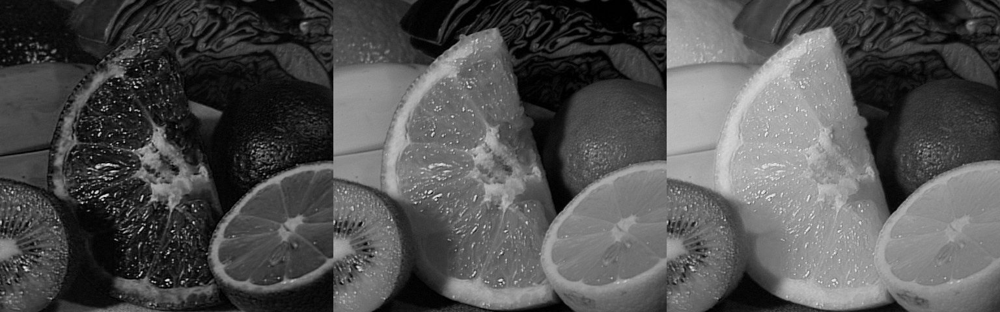

In [43]:
b, g, r = cv2.split(img)
cv2_imshow(np.hstack([b, g, r]))   # синий | зелёный | красный

### ✏️ Задание 12. Соберите картинку, поменяв местами синий и красный каналы

In [44]:
swapped = cv2.merge([r, g, b])

✅ Тест 1: картинка собрана
✅ Тест 2: синий и красный поменялись

🎉 Задание 12 выполнено! Пройдено тестов: 2 из 2


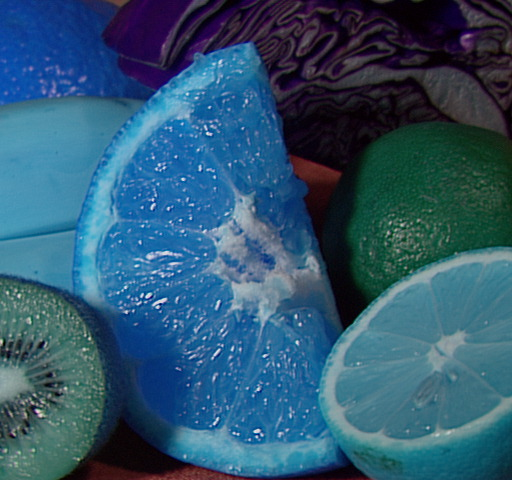

In [45]:
#@title 🧪 Проверка задания 12 { display-mode: "form" }
def _check(tests):
    for i, (name, cond, hint) in enumerate(tests, 1):
        try:
            passed = bool(cond())
        except Exception:
            passed = False
        if not passed:
            print(f"❌ Тест {i} из {len(tests)}: {name}")
            print(f"   💡 {hint}")
            return False
        print(f"✅ Тест {i}: {name}")
    print(f"\n🎉 Задание 12 выполнено! Пройдено тестов: {len(tests)} из {len(tests)}")
    return True

if _check([
    ('картинка собрана', lambda: swapped is not None and swapped.shape == img.shape, 'cv2.merge([канал, канал, канал])'),
    ('синий и красный поменялись', lambda: (swapped == img[:, :, ::-1]).all(), 'Обычный порядок [b, g, r] — поменяйте первый и последний'),
]):
    cv2_imshow(swapped)

<details><summary>💡 Подсказка</summary>

Апельсины должны посинеть — так выглядит путаница BGR и RGB.
</details>
<details><summary>🆘 Почти готовый ответ</summary>

```python
swapped = cv2.merge([___, g, ___])
```
</details>

## 12. Яркость и ловушка переполнения
`uint8` не умеет больше 255: `200 + 100` превращается в `44` (число «перескакивает» через ноль). Поэтому яркость меняем через `cv2.convertScaleAbs(img, alpha=контраст, beta=яркость)` — он обрезает результат до 0…255.

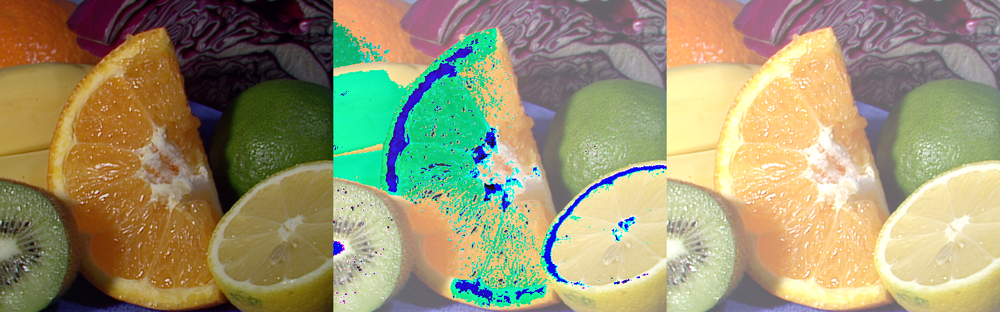

In [55]:
wrong = img + 100                                       # ❌ светлое стало тёмным
right = cv2.convertScaleAbs(img, alpha=1.0, beta=100)   # ✅ просто ярче
cv2_imshow(np.hstack([img, wrong, right]))

### ✏️ Задание 13. Сделайте картинку темнее на 60

In [47]:
dark = cv2.convertScaleAbs(img, alpha=1.0, beta= 60)

In [48]:
#@title 🧪 Проверка задания 13 { display-mode: "form" }
def _check(tests):
    for i, (name, cond, hint) in enumerate(tests, 1):
        try:
            passed = bool(cond())
        except Exception:
            passed = False
        if not passed:
            print(f"❌ Тест {i} из {len(tests)}: {name}")
            print(f"   💡 {hint}")
            return False
        print(f"✅ Тест {i}: {name}")
    print(f"\n🎉 Задание 13 выполнено! Пройдено тестов: {len(tests)} из {len(tests)}")
    return True

if _check([
    ('картинка получена', lambda: dark is not None, 'Используйте cv2.convertScaleAbs'),
    ('темнее ровно на 60', lambda: (dark == cv2.convertScaleAbs(img, alpha=1.0, beta=-60)).all(), 'Темнее — beta с минусом: beta=-60'),
]):
    cv2_imshow(dark)

✅ Тест 1: картинка получена
❌ Тест 2 из 2: темнее ровно на 60
   💡 Темнее — beta с минусом: beta=-60


<details><summary>💡 Подсказка</summary>

`beta` — сколько прибавить. Темнее — значит отнять.
</details>
<details><summary>🆘 Почти готовый ответ</summary>

```python
dark = cv2.convertScaleAbs(img, alpha=1.0, beta=___)
```
</details>

### ✏️ Задание 14. Усильте **только красный** канал на 10% (задание контрольной!)

In [70]:
warm = img.copy()
warm[:, :, 2] = cv2.convertScaleAbs(img[:, :, 2], alpha=1.1)

✅ Тест 1: красный канал ×1.1
✅ Тест 2: синий и зелёный не тронуты

🎉 Задание 14 выполнено! Пройдено тестов: 2 из 2


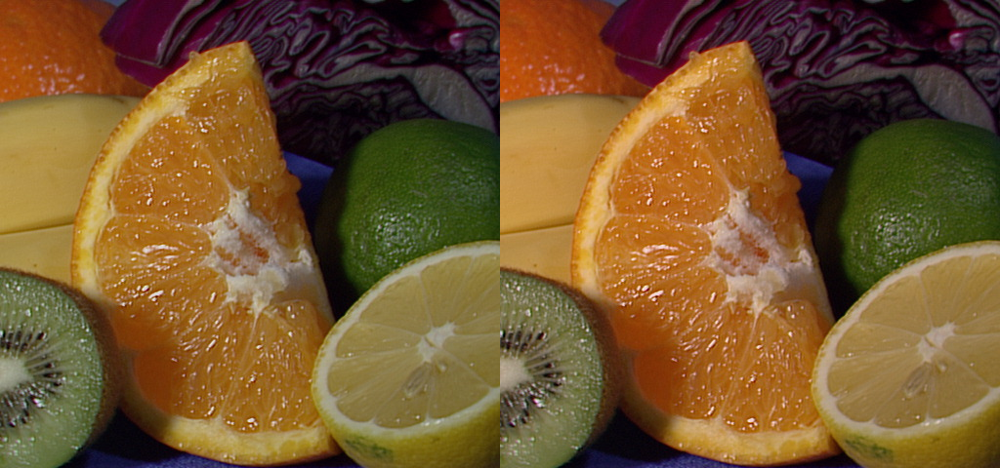

In [71]:
#@title 🧪 Проверка задания 14 { display-mode: "form" }
def _check(tests):
    for i, (name, cond, hint) in enumerate(tests, 1):
        try:
            passed = bool(cond())
        except Exception:
            passed = False
        if not passed:
            print(f"❌ Тест {i} из {len(tests)}: {name}")
            print(f"   💡 {hint}")
            return False
        print(f"✅ Тест {i}: {name}")
    print(f"\n🎉 Задание 14 выполнено! Пройдено тестов: {len(tests)} из {len(tests)}")
    return True

if _check([
    ('красный канал ×1.1', lambda: (warm[:, :, 2] == cv2.convertScaleAbs(img[:, :, 2], alpha=1.1)).all(), 'Красный — индекс 2. alpha=1.1 — это ×1.1'),
    ('синий и зелёный не тронуты', lambda: (warm[:, :, :2] == img[:, :, :2]).all(), 'Меняйте только warm[:, :, 2]'),
]):
    cv2_imshow(np.hstack([img, warm]))

<details><summary>💡 Подсказка</summary>

Берём `img[:, :, 2]`, пропускаем через `convertScaleAbs(..., alpha=1.1)` и кладём в `warm[:, :, 2]`.
</details>
<details><summary>🆘 Почти готовый ответ</summary>

```python
warm[:, :, 2] = cv2.convertScaleAbs(img[:, :, ___], alpha=___)
```
</details>

## 13. Рисуем
| Что | Как |
|---|---|
| линия | `cv2.line(img, (x1, y1), (x2, y2), цвет, толщина)` |
| прямоугольник | `cv2.rectangle(img, (x1, y1), (x2, y2), цвет, толщина)` |
| круг | `cv2.circle(img, (x, y), радиус, цвет, толщина)` |
| текст | `cv2.putText(img, "text", (x, y), шрифт, размер, цвет, толщина)` |

⚠️ Здесь точки пишутся **(x, y)** — сначала по горизонтали (а в `img[y, x]` наоборот). Толщина `-1` — залить. `putText` не знает русских букв.

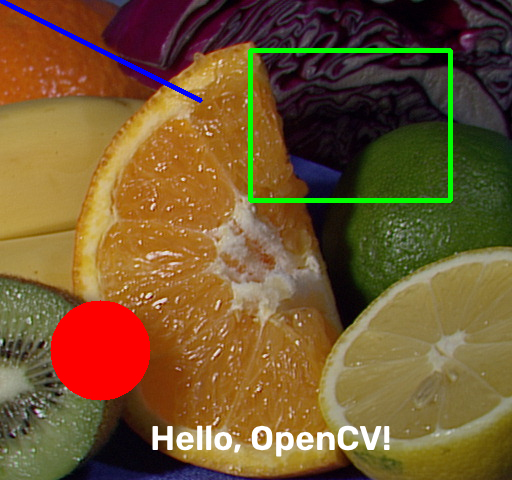

In [58]:
art = img.copy()
cv2.line(art, (0, 0), (200, 100), (255, 0, 0), 3)
cv2.rectangle(art, (250, 50), (450, 200), (0, 255, 0), 4)
cv2.circle(art, (100, 350), 50, (0, 0, 255), -1)
cv2.putText(art, "Hello, OpenCV!", (150, 450), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (255, 255, 255), 3)
cv2_imshow(art)

### ✏️ Задание 15. Оформите постер: рамка по краю (толщина 10), залитый круг радиусом 30 в центре, ваше имя латиницей внизу

array([[[ 60, 200, 255],
        [ 60, 200, 255],
        [ 60, 200, 255],
        ...,
        [ 60, 200, 255],
        [ 60, 200, 255],
        [ 60, 200, 255]],

       [[ 60, 200, 255],
        [ 60, 200, 255],
        [ 60, 200, 255],
        ...,
        [ 60, 200, 255],
        [ 60, 200, 255],
        [ 60, 200, 255]],

       [[ 60, 200, 255],
        [ 60, 200, 255],
        [ 60, 200, 255],
        ...,
        [ 60, 200, 255],
        [ 60, 200, 255],
        [ 60, 200, 255]],

       ...,

       [[ 60, 200, 255],
        [ 60, 200, 255],
        [ 60, 200, 255],
        ...,
        [ 60, 200, 255],
        [ 60, 200, 255],
        [ 60, 200, 255]],

       [[ 60, 200, 255],
        [ 60, 200, 255],
        [ 60, 200, 255],
        ...,
        [ 60, 200, 255],
        [ 60, 200, 255],
        [ 60, 200, 255]],

       [[ 60, 200, 255],
        [ 60, 200, 255],
        [ 60, 200, 255],
        ...,
        [ 60, 200, 255],
        [ 60, 200, 255],
        [ 60, 200, 255]]], dtype=uint8)
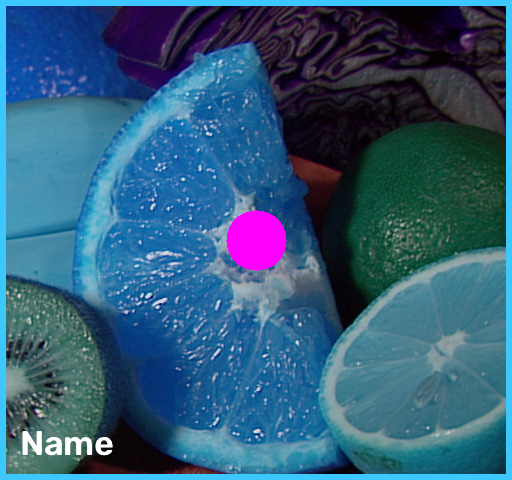

In [59]:
poster = img.copy()
# ↓ ваш код
cv2.rectangle(poster, (0, 0), (w - 1, h - 1), (60, 200, 255), 10)
cv2.circle(poster, (w // 2, h // 2), 30, (255, 0, 255), -1)
cv2.putText(poster, "Name", (20, h - 25), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (255, 255, 255), 3)


✅ Тест 1: есть рамка сверху
✅ Тест 2: есть рамка снизу
✅ Тест 3: в центре залитый круг

🎉 Задание 15 выполнено! Пройдено тестов: 3 из 3


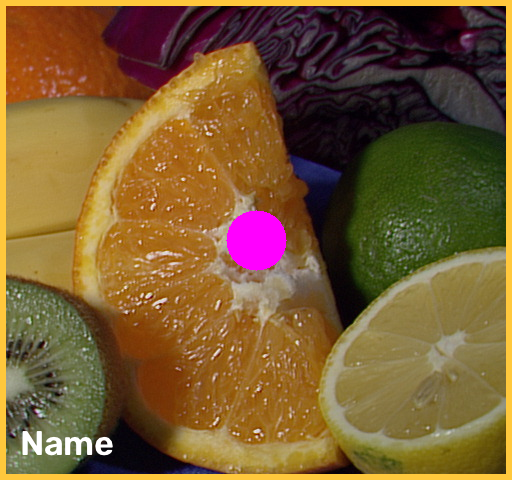

In [60]:
#@title 🧪 Проверка задания 15 { display-mode: "form" }
def _check(tests):
    for i, (name, cond, hint) in enumerate(tests, 1):
        try:
            passed = bool(cond())
        except Exception:
            passed = False
        if not passed:
            print(f"❌ Тест {i} из {len(tests)}: {name}")
            print(f"   💡 {hint}")
            return False
        print(f"✅ Тест {i}: {name}")
    print(f"\n🎉 Задание 15 выполнено! Пройдено тестов: {len(tests)} из {len(tests)}")
    return True

if _check([
    ('есть рамка сверху', lambda: (poster[2, w // 2] != img[2, w // 2]).any(), 'Прямоугольник от (0, 0) до (w - 1, h - 1), толщина 10'),
    ('есть рамка снизу', lambda: (poster[h - 3, w // 3] != img[h - 3, w // 3]).any(), 'Правый нижний угол рамки — (w - 1, h - 1)'),
    ('в центре залитый круг', lambda: (poster[h // 2, w // 2] != img[h // 2, w // 2]).any() and (poster[h // 2 + 20, w // 2] != img[h // 2 + 20, w // 2]).any(), 'Центр (w // 2, h // 2), радиус 30, толщина -1'),
]):
    cv2_imshow(poster)

<details><summary>💡 Подсказка</summary>

Рамка: `(0, 0)` → `(w - 1, h - 1)`. Круг: центр `(w // 2, h // 2)`, толщина `-1`. Текст: точка `(20, h - 25)`.
</details>
<details><summary>🆘 Почти готовый ответ</summary>

```python
cv2.rectangle(poster, (0, 0), (w - 1, h - 1), (60, 200, 255), ___)
cv2.circle(poster, (w // 2, h // 2), 30, (255, 0, 255), ___)
cv2.putText(poster, "Name", (20, h - 25), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (255, 255, 255), 3)
```
</details>

## 14. Сохранить — `cv2.imwrite`
`cv2.imwrite("имя.jpg", картинка)`. Файл появится слева во вкладке 📁.

### ✏️ Задание 16. Сохраните постер в файл `poster.jpg`

In [72]:
# ↓ ваш код
cv2.imwrite("poster.jpg", poster)

True

In [73]:
#@title 🧪 Проверка задания 16 { display-mode: "form" }
def _check(tests):
    for i, (name, cond, hint) in enumerate(tests, 1):
        try:
            passed = bool(cond())
        except Exception:
            passed = False
        if not passed:
            print(f"❌ Тест {i} из {len(tests)}: {name}")
            print(f"   💡 {hint}")
            return False
        print(f"✅ Тест {i}: {name}")
    print(f"\n🎉 Задание 16 выполнено! Пройдено тестов: {len(tests)} из {len(tests)}")
    return True

if _check([
    ('файл poster.jpg существует', lambda: __import__('os').path.exists('poster.jpg'), 'cv2.imwrite("poster.jpg", poster)'),
    ('в файле ваш постер', lambda: cv2.imread('poster.jpg').shape == poster.shape, 'Сохраните именно poster'),
]):
    pass

✅ Тест 1: файл poster.jpg существует
✅ Тест 2: в файле ваш постер

🎉 Задание 16 выполнено! Пройдено тестов: 2 из 2


<details><summary>💡 Подсказка</summary>

Сначала имя файла в кавычках, потом картинка.
</details>
<details><summary>🆘 Почти готовый ответ</summary>

```python
cv2.imwrite("poster.jpg", ___)
```
</details>

---
# Часть 2. Видео
**Видео — это много картинок (кадров) подряд.** Всё из части 1 работает с каждым кадром.

## 15. Открыть видео — `cv2.VideoCapture`
`VideoCapture` — как проигрыватель: видео не грузится в память сразу, кадры достаём по одному.

In [75]:
!wget -q -nc https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/vtest.avi
cap = cv2.VideoCapture("vtest.avi")
print("Видео открылось?", cap.isOpened())

Видео открылось? True


## 16. Свойства видео — `cap.get`

In [76]:
fps = cap.get(cv2.CAP_PROP_FPS)              # кадров в секунду
count = cap.get(cv2.CAP_PROP_FRAME_COUNT)    # всего кадров
width = cap.get(cv2.CAP_PROP_FRAME_WIDTH)
height = cap.get(cv2.CAP_PROP_FRAME_HEIGHT)
print("FPS:", fps, " кадров:", count, " размер:", width, "×", height)

FPS: 10.0  кадров: 795.0  размер: 768.0 × 576.0


### ✏️ Задание 17. Сколько секунд длится видео?

In [79]:
duration = count / fps

In [80]:
#@title 🧪 Проверка задания 17 { display-mode: "form" }
def _check(tests):
    for i, (name, cond, hint) in enumerate(tests, 1):
        try:
            passed = bool(cond())
        except Exception:
            passed = False
        if not passed:
            print(f"❌ Тест {i} из {len(tests)}: {name}")
            print(f"   💡 {hint}")
            return False
        print(f"✅ Тест {i}: {name}")
    print(f"\n🎉 Задание 17 выполнено! Пройдено тестов: {len(tests)} из {len(tests)}")
    return True

if _check([
    ('длительность верная', lambda: abs(duration - count / fps) < 1e-6, 'Кадров count, в секунде fps кадров. Делим'),
]):
    print("Длительность:", duration, "с")

✅ Тест 1: длительность верная

🎉 Задание 17 выполнено! Пройдено тестов: 1 из 1
Длительность: 79.5 с


<details><summary>💡 Подсказка</summary>

FPS — кадров в одной секунде.
</details>
<details><summary>🆘 Почти готовый ответ</summary>

```python
duration = count / ___
```
</details>

## 17. Достать кадр — `cap.read()`
`ok, frame = cap.read()` возвращает **два** значения: получилось ли (`True`/`False`) и сам кадр. Каждый вызов даёт **следующий** кадр.

Прочитали? True  размер: (576, 768, 3)


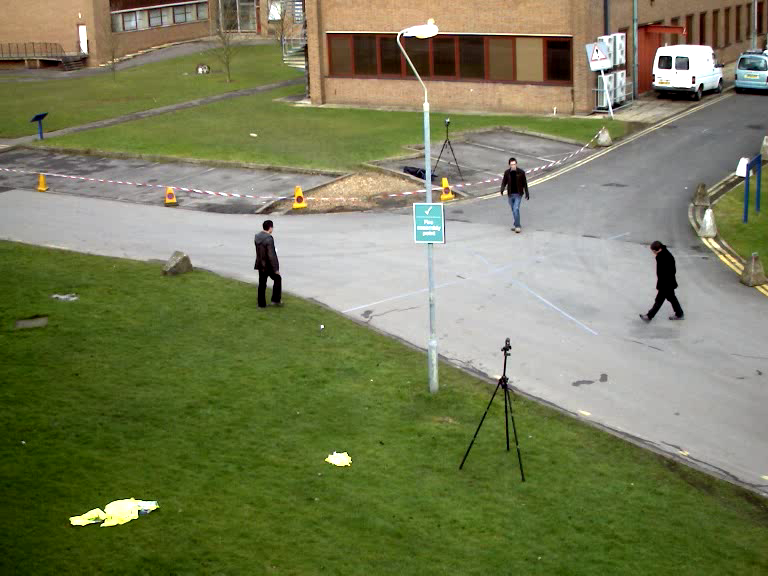

In [81]:
ok, frame = cap.read()
print("Прочитали?", ok, " размер:", frame.shape)
cv2_imshow(frame)

### ✏️ Задание 18. Прочитайте следующий кадр в переменные `ok2`, `frame2`

In [85]:
ok2, frame2 = cap.read()


✅ Тест 1: кадр прочитан (ok2 == True)
✅ Тест 2: это кадр того же размера
✅ Тест 3: это уже другой кадр

🎉 Задание 18 выполнено! Пройдено тестов: 3 из 3


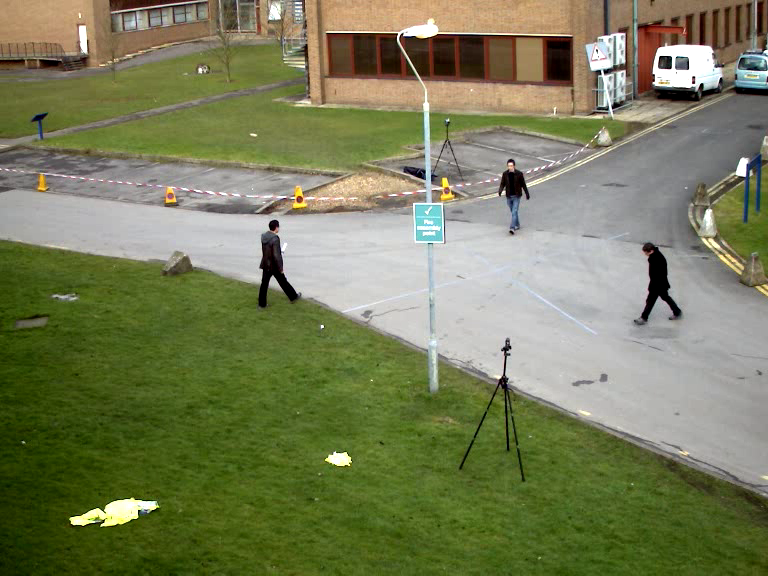

In [83]:
#@title 🧪 Проверка задания 18 { display-mode: "form" }
def _check(tests):
    for i, (name, cond, hint) in enumerate(tests, 1):
        try:
            passed = bool(cond())
        except Exception:
            passed = False
        if not passed:
            print(f"❌ Тест {i} из {len(tests)}: {name}")
            print(f"   💡 {hint}")
            return False
        print(f"✅ Тест {i}: {name}")
    print(f"\n🎉 Задание 18 выполнено! Пройдено тестов: {len(tests)} из {len(tests)}")
    return True

if _check([
    ('кадр прочитан (ok2 == True)', lambda: ok2 is True, 'ok2, frame2 = cap.read()'),
    ('это кадр того же размера', lambda: frame2.shape == frame.shape, 'frame2 — вторая переменная из cap.read()'),
    ('это уже другой кадр', lambda: (frame2 != frame).any(), 'Каждый cap.read() даёт следующий кадр'),
]):
    cv2_imshow(frame2)

<details><summary>💡 Подсказка</summary>

Скопируйте строку из примера и поменяйте имена переменных.
</details>
<details><summary>🆘 Почти готовый ответ</summary>

```python
ok2, frame2 = cap.___()
```
</details>

## 18. Кадр по номеру — `cap.set`
`cap.set(cv2.CAP_PROP_POS_FRAMES, номер)` перематывает видео, потом делаем `read()`.

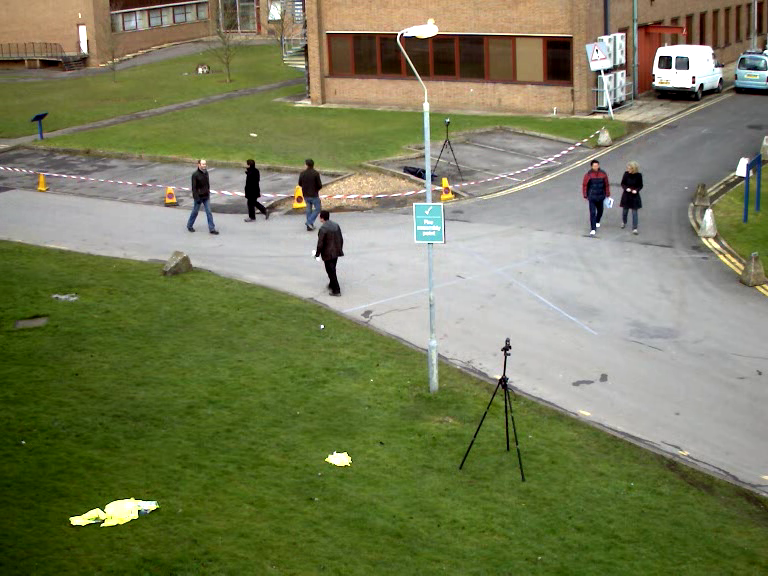

In [84]:
cap.set(cv2.CAP_PROP_POS_FRAMES, 300)
ok, frame300 = cap.read()
cv2_imshow(frame300)

### ✏️ Задание 19. Достаньте кадр из середины видео

In [87]:
middle = int(count // 2)    # ← замените 0 на номер среднего кадра (целое число)
cap.set(cv2.CAP_PROP_POS_FRAMES, middle)
ok, frame_mid = cap.read()

✅ Тест 1: номер — середина видео
✅ Тест 2: кадр прочитан

🎉 Задание 19 выполнено! Пройдено тестов: 2 из 2


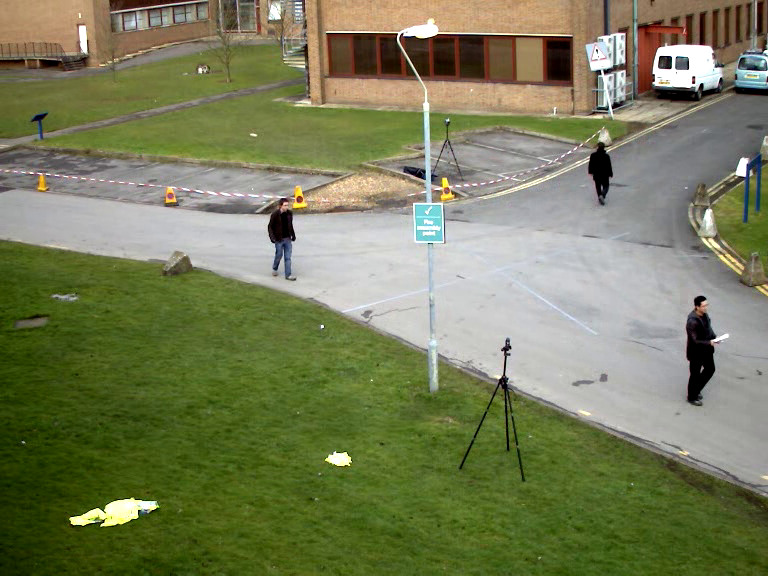

In [88]:
#@title 🧪 Проверка задания 19 { display-mode: "form" }
def _check(tests):
    for i, (name, cond, hint) in enumerate(tests, 1):
        try:
            passed = bool(cond())
        except Exception:
            passed = False
        if not passed:
            print(f"❌ Тест {i} из {len(tests)}: {name}")
            print(f"   💡 {hint}")
            return False
        print(f"✅ Тест {i}: {name}")
    print(f"\n🎉 Задание 19 выполнено! Пройдено тестов: {len(tests)} из {len(tests)}")
    return True

if _check([
    ('номер — середина видео', lambda: middle == int(count // 2), 'Половина от count, нацело: int(count // 2)'),
    ('кадр прочитан', lambda: frame_mid is not None, 'Запустите ячейку задания целиком'),
]):
    cv2_imshow(frame_mid)

<details><summary>💡 Подсказка</summary>

Середина — половина от `count`. Номер должен быть целым: `int(...)`.
</details>
<details><summary>🆘 Почти готовый ответ</summary>

```python
middle = int(count // ___)
```
</details>

## 19. Главный цикл: читаем много кадров

In [89]:
cap = cv2.VideoCapture("vtest.avi")   # открываем заново, с начала
frames = []                           # сюда сложим кадры

while len(frames) < 80:               # первые 80 кадров (8 секунд)
    ok, frame = cap.read()            # очередной кадр
    if not ok:                        # видео кончилось — выходим
        break
    frame = cv2.resize(frame, (384, 288))   # уменьшаем: быстрее считать и показывать
    frames.append(frame)              # кладём в список

cap.release()                         # закрываем видео
print("Прочитано кадров:", len(frames))

Прочитано кадров: 80


## 20. Смотрим видео в Colab
В Colab нет окна, поэтому видео покажем плеером. Ячейка ниже добавляет функцию `show_video(кадры)`: она склеивает кадры в маленький mp4. **Просто запустите её** — как она устроена внутри, сейчас не важно.

In [90]:
#@title ▶️ Запустите: функция show_video { display-mode: "form" }
import base64, subprocess
from IPython.display import HTML, display

def show_video(frames, fps=10, width=480):
    """Склеивает список кадров в mp4 и показывает плеером."""
    if len(frames) == 0 or any(f is None for f in frames):
        print("⚠️ Показывать нечего: список пуст или в нём None")
        return
    prep = []
    for f in frames:
        if f.ndim == 2:                                   # серый кадр → три канала
            f = cv2.cvtColor(f, cv2.COLOR_GRAY2BGR)
        h, w = f.shape[:2]
        prep.append(np.ascontiguousarray(f[: h - h % 2, : w - w % 2]))
    h, w = prep[0].shape[:2]
    cmd = ["ffmpeg", "-y", "-loglevel", "error", "-f", "rawvideo", "-pix_fmt", "bgr24", "-s", f"{w}x{h}",
           "-r", str(fps), "-i", "-", "-c:v", "libx264", "-pix_fmt", "yuv420p", "-crf", "30",
           "-movflags", "+faststart", "-f", "mp4", "-"]
    data = subprocess.run(cmd, input=b"".join(f.tobytes() for f in prep), capture_output=True).stdout
    b64 = base64.b64encode(data).decode()
    display(HTML(f'<video width="{width}" controls autoplay loop muted><source src="data:video/mp4;base64,{b64}" type="video/mp4"></video>'))

print("✅ Функция show_video готова")

✅ Функция show_video готова


In [91]:
show_video(frames, fps=10)

### ✏️ Задание 20. Сколько секунд длится наш кусочек из 80 кадров?

In [98]:
clip_seconds = len(frames) / 10

In [99]:
#@title 🧪 Проверка задания 20 { display-mode: "form" }
def _check(tests):
    for i, (name, cond, hint) in enumerate(tests, 1):
        try:
            passed = bool(cond())
        except Exception:
            passed = False
        if not passed:
            print(f"❌ Тест {i} из {len(tests)}: {name}")
            print(f"   💡 {hint}")
            return False
        print(f"✅ Тест {i}: {name}")
    print(f"\n🎉 Задание 20 выполнено! Пройдено тестов: {len(tests)} из {len(tests)}")
    return True

if _check([
    ('длительность верная', lambda: abs(clip_seconds - len(frames) / fps) < 1e-6, 'Как в задании 17: кадров len(frames), делим на fps'),
]):
    print("Секунд:", clip_seconds)

✅ Тест 1: длительность верная

🎉 Задание 20 выполнено! Пройдено тестов: 1 из 1
Секунд: 8.0


<details><summary>💡 Подсказка</summary>

Число кадров — `len(frames)`.
</details>
<details><summary>🆘 Почти готовый ответ</summary>

```python
clip_seconds = len(frames) / ___
```
</details>

## 21. Меняем каждый кадр
Шаблон обработки видео: **взять кадр → изменить → положить в новый список**.

In [100]:
result = []
for frame in frames:             # для каждого кадра
    new = cv2.flip(frame, 1)     # меняем
    result.append(new)           # кладём в результат
show_video(result)

### ✏️ Задание 21. Сделайте видео чёрно-белым

In [104]:
gray_video = []
for frame in frames:
 new = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)      # ← серый кадр (как в задании 11)
 gray_video.append(new)

In [105]:
#@title 🧪 Проверка задания 21 { display-mode: "form" }
def _check(tests):
    for i, (name, cond, hint) in enumerate(tests, 1):
        try:
            passed = bool(cond())
        except Exception:
            passed = False
        if not passed:
            print(f"❌ Тест {i} из {len(tests)}: {name}")
            print(f"   💡 {hint}")
            return False
        print(f"✅ Тест {i}: {name}")
    print(f"\n🎉 Задание 21 выполнено! Пройдено тестов: {len(tests)} из {len(tests)}")
    return True

if _check([
    ('кадров столько же', lambda: len(gray_video) == len(frames), 'Каждый кадр нужно добавить в gray_video'),
    ('кадры серые', lambda: all(f is not None and f.ndim == 2 for f in gray_video), 'new = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)'),
]):
    show_video(gray_video)

✅ Тест 1: кадров столько же
✅ Тест 2: кадры серые

🎉 Задание 21 выполнено! Пройдено тестов: 2 из 2


<details><summary>💡 Подсказка</summary>

Внутри цикла та же строка, что в задании 11, только для `frame`.
</details>
<details><summary>🆘 Почти готовый ответ</summary>

```python
    new = cv2.cvtColor(frame, cv2.___)
```
</details>

### ✏️ Задание 22. Напишите номер на каждом кадре (`frame 0`, `frame 1`, …)

In [125]:
numbered = []
for i, frame in enumerate(frames):   # enumerate даёт номер i и кадр
    new = frame.copy()
    # ↓ ваш код: cv2.putText(new, f"frame {i}", ...)
    cv2.putText(new, f"frame {i}", (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2 )

    numbered.append(new)

In [126]:
#@title 🧪 Проверка задания 22 { display-mode: "form" }
def _check(tests):
    for i, (name, cond, hint) in enumerate(tests, 1):
        try:
            passed = bool(cond())
        except Exception:
            passed = False
        if not passed:
            print(f"❌ Тест {i} из {len(tests)}: {name}")
            print(f"   💡 {hint}")
            return False
        print(f"✅ Тест {i}: {name}")
    print(f"\n🎉 Задание 22 выполнено! Пройдено тестов: {len(tests)} из {len(tests)}")
    return True

if _check([
    ('кадров столько же', lambda: len(numbered) == len(frames), 'Не потеряйте numbered.append(new)'),
    ('на кадрах есть надпись', lambda: all((numbered[k] != frames[k]).any() for k in (0, 40, 79)), 'cv2.putText(new, f"frame {i}", (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2)'),
]):
    show_video(numbered)

✅ Тест 1: кадров столько же
✅ Тест 2: на кадрах есть надпись

🎉 Задание 22 выполнено! Пройдено тестов: 2 из 2


<details><summary>💡 Подсказка</summary>

`f"frame {i}"` — строка, в которую подставится номер. Точка, например, `(10, 30)`.
</details>
<details><summary>🆘 Почти готовый ответ</summary>

```python
    cv2.putText(new, f"frame {i}", (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), ___)
```
</details>

### ✏️ Задание 23. Переверните всё видео на 180°

In [127]:
upside_video = []
# ↓ ваш цикл
for frame in frames:
    upside_video.append(cv2.flip(frame, -1))


In [128]:
#@title 🧪 Проверка задания 23 { display-mode: "form" }
def _check(tests):
    for i, (name, cond, hint) in enumerate(tests, 1):
        try:
            passed = bool(cond())
        except Exception:
            passed = False
        if not passed:
            print(f"❌ Тест {i} из {len(tests)}: {name}")
            print(f"   💡 {hint}")
            return False
        print(f"✅ Тест {i}: {name}")
    print(f"\n🎉 Задание 23 выполнено! Пройдено тестов: {len(tests)} из {len(tests)}")
    return True

if _check([
    ('кадров столько же', lambda: len(upside_video) == len(frames), 'Нужен цикл for frame in frames: ...'),
    ('кадры перевёрнуты на 180°', lambda: (upside_video[0] == cv2.flip(frames[0], -1)).all() and (upside_video[-1] == cv2.flip(frames[-1], -1)).all(), 'Код поворота на 180° — из задания 9'),
]):
    show_video(upside_video)

✅ Тест 1: кадров столько же
✅ Тест 2: кадры перевёрнуты на 180°

🎉 Задание 23 выполнено! Пройдено тестов: 2 из 2


<details><summary>💡 Подсказка</summary>

Скопируйте цикл из примера с зеркалом, поменяйте код отражения.
</details>
<details><summary>🆘 Почти готовый ответ</summary>

```python
for frame in frames:
    upside_video.append(cv2.flip(frame, ___))
```
</details>

## 22. Сохранить видео — `cv2.VideoWriter`
«Записыватель» видео. Нужны: имя файла, кодек (`mp4v`), FPS и размер `(ширина, высота)`. Кладём кадры через `write`, в конце **обязательно** `release()` — иначе файл будет битым.

In [129]:
from google.colab import files   # чтобы скачать файл к себе

h, w = result[0].shape[:2]
out = cv2.VideoWriter("mirror.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
for frame in result:
    out.write(frame)
out.release()
files.download("mirror.mp4")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### ✏️ Задание 24. Сохраните видео с номерами кадров в `numbered.mp4`

In [131]:
# ↓ скопируйте пример выше и поменяйте имя файла и список кадров
h, w = numbered[0].shape[:2]
out = cv2.VideoWriter("numbered.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
for frame in numbered:
    out.write(frame)
out.release()

In [132]:
#@title 🧪 Проверка задания 24 { display-mode: "form" }
def _check(tests):
    for i, (name, cond, hint) in enumerate(tests, 1):
        try:
            passed = bool(cond())
        except Exception:
            passed = False
        if not passed:
            print(f"❌ Тест {i} из {len(tests)}: {name}")
            print(f"   💡 {hint}")
            return False
        print(f"✅ Тест {i}: {name}")
    print(f"\n🎉 Задание 24 выполнено! Пройдено тестов: {len(tests)} из {len(tests)}")
    return True

if _check([
    ('файл numbered.mp4 создан', lambda: __import__('os').path.exists('numbered.mp4'), 'Имя файла — "numbered.mp4"'),
    ('в файле все кадры', lambda: cv2.VideoCapture('numbered.mp4').get(cv2.CAP_PROP_FRAME_COUNT) == len(numbered), 'Цикл по numbered и out.release() в конце'),
]):
    pass

✅ Тест 1: файл numbered.mp4 создан
✅ Тест 2: в файле все кадры

🎉 Задание 24 выполнено! Пройдено тестов: 2 из 2


<details><summary>💡 Подсказка</summary>

Поменяйте две вещи: `"mirror.mp4"` → `"numbered.mp4"` и `result` → `numbered`.
</details>
<details><summary>🆘 Почти готовый ответ</summary>

```python
h, w = numbered[0].shape[:2]
out = cv2.VideoWriter("numbered.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
for frame in ___:
    out.write(frame)
out.release()
```
</details>

## 23. По желанию: своё видео
Загрузите **короткий** ролик (до 5 секунд — интернет общий). Потом прочитайте его циклом из шага 19 и повторите задания 21–23.

In [133]:
# uploaded = files.upload()          # откроется окно выбора файла
# my_name = list(uploaded)[0]        # имя загруженного файла
# cap = cv2.VideoCapture(my_name)

---
# Как это выглядит на обычном компьютере
С установленным OpenCV видео показывают в окне и берут прямо с веб-камеры. Здесь не запускаем (в Colab нет окна), но **по этому шаблону будет контрольная**: клавиша включает и выключает эффект.

```python
import cv2

cap = cv2.VideoCapture(0)              # 0 — веб-камера
flipped = False                        # включён ли эффект

while True:
    ok, frame = cap.read()
    if not ok:
        break

    key = cv2.waitKey(1) & 0xFF        # какая клавиша нажата (ждём 1 мс)
    if key == ord("t"):                # нажали t — переключаем
        flipped = not flipped          # False → True → False
    if key == ord("q"):                # q — выход
        break

    if flipped:
        frame = cv2.flip(frame, -1)
    cv2.imshow("video", frame)

cap.release()
cv2.destroyAllWindows()
```

---
# 🏠 Домашнее задание (КТ 1): «Свой видео-продакшн»
**Сдать в LXP:** ссылку на ноутбук (Настройки доступа → «Все, у кого есть ссылка») и файл `production.mp4`.

| № | Что сделать | Баллы |
|---|---|---|
| 1 | На **каждом** кадре — подпись латиницей и **логотип** 50×50 в правом верхнем углу (вставить срезом, как в задании 6). Логотип появляется **только со 2-й секунды** | 1 |
| 2 | **Таймер с тенью** в левом верхнем углу: `00:03`. Сначала тёмный текст со сдвигом на 2 пикселя (тень), потом светлый. Шрифт и цвет — свои | 1 |

<details><summary>💡 Подсказки</summary>

* Секунда кадра: `sec = int(i / fps)`. Логотип со 2-й секунды: `if i >= 2 * fps:`.
* Вставка: `new[10:60, w - 60:w - 10] = logo` — кусок и логотип одного размера 50×50.
* Время строкой: `f"{sec // 60:02d}:{sec % 60:02d}"` → `00:03`.
* Шрифты: `cv2.FONT_HERSHEY_DUPLEX`, `cv2.FONT_HERSHEY_COMPLEX`, `cv2.FONT_HERSHEY_TRIPLEX`.
</details>

In [136]:
logo = np.full((50, 50, 3), (60, 200, 255), np.uint8)    # жёлтый квадрат 50×50
cv2.putText(logo, "A", (12, 38), cv2.FONT_HERSHEY_DUPLEX, 1.2, (40, 30, 30), 2)

production = []
for i, frame in enumerate(frames):
    new = frame.copy()
    h, w = new.shape[:2]
    # 1. подпись и логотип (со 2-й секунды)

    # 2. таймер с тенью

    production.append(new)

In [135]:
#@title 🧪 Самопроверка КТ 1 { display-mode: "form" }
_W = frames[0].shape[1]
_tests = [
    ("кадров столько же, сколько в видео", lambda: len(production) == len(frames)),
    ("в первую секунду логотипа нет", lambda: not (production[0][10:60, _W - 60:_W - 10] == logo).all()),
    ("со 2-й секунды логотип в правом верхнем углу", lambda: (production[int(2 * fps) + 1][10:60, _W - 60:_W - 10] == logo).all()),
    ("в левом верхнем углу что-то написано (таймер)", lambda: (production[0][5:40, 5:120] != frames[0][5:40, 5:120]).any()),
]
_done = 0
for _i, (_name, _cond) in enumerate(_tests, 1):
    try:
        _res = bool(_cond())
    except Exception:
        _res = False
    print(("✅" if _res else "❌"), f"Тест {_i}: {_name}")
    _done += _res
print(f"\nПройдено {_done} из {len(_tests)}")
if _done == len(_tests):
    show_video(production)

✅ Тест 1: кадров столько же, сколько в видео
✅ Тест 2: в первую секунду логотипа нет
❌ Тест 3: со 2-й секунды логотип в правом верхнем углу
❌ Тест 4: в левом верхнем углу что-то написано (таймер)

Пройдено 2 из 4


In [ ]:
h, w = production[0].shape[:2]
out = cv2.VideoWriter("production.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
for frame in production:
    out.write(frame)
out.release()
files.download("production.mp4")

---
# 📋 Шпаргалка cv2

| Задача | Код |
|---|---|
| открыть картинку | `img = cv2.imread("file.jpg")` |
| показать в Colab | `cv2_imshow(img)` |
| размер | `h, w, c = img.shape` (высота, ширина, каналы) |
| пиксель | `img[y, x]` → `[B, G, R]` |
| закрасить кусок | `img[y1:y2, x1:x2] = (B, G, R)` |
| вырезать кусок | `piece = img[y1:y2, x1:x2]` |
| копия | `img.copy()` |
| изменить размер | `cv2.resize(img, (ширина, высота))` |
| отразить | `cv2.flip(img, 1)` ↔, `0` ↕, `-1` = 180° |
| повернуть на 90° | `cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)` |
| серый | `cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)` |
| каналы | `b, g, r = cv2.split(img)` · `cv2.merge([b, g, r])` |
| яркость | `cv2.convertScaleAbs(img, alpha=1.0, beta=50)` |
| линия / рамка / круг | `cv2.line` · `cv2.rectangle` · `cv2.circle` |
| текст | `cv2.putText(img, "text", (x, y), cv2.FONT_HERSHEY_SIMPLEX, 1, (B, G, R), 2)` |
| сохранить картинку | `cv2.imwrite("out.jpg", img)` |
| открыть видео | `cap = cv2.VideoCapture("video.mp4")` (или `0` — камера) |
| свойства | `cap.get(cv2.CAP_PROP_FPS)` · `CAP_PROP_FRAME_COUNT` · `CAP_PROP_FRAME_WIDTH` |
| прочитать кадр | `ok, frame = cap.read()` |
| перемотать | `cap.set(cv2.CAP_PROP_POS_FRAMES, n)` |
| записать видео | `out = cv2.VideoWriter("out.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))` → `out.write(frame)` → `out.release()` |
| показать видео в Colab | `show_video(frames)` |